In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
df = pd.read_csv("NaturalGas.csv")

print(df.head())

   rownames state  statecode  year  consumption  price  eprice  oprice  \
0         1    NY         35  1967       313656   1.42    2.98    7.40   
1         2    NY         35  1968       319282   1.38    2.91    7.77   
2         3    NY         35  1969       331326   1.37    2.84    7.96   
3         4    NY         35  1970       346533   1.40    2.87    8.33   
4         5    NY         35  1971       352085   1.50    3.07    8.80   

   lprice  heating    income  
0    1.47     6262  10903.75  
1    1.42     6125  11370.02  
2    1.38     6040  11578.68  
3    1.37     6085  11586.77  
4    1.40     5907  11657.42  


In [ ]:
print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
print(df.info())

Shape:
(138, 11)

Columns:
Index(['rownames', 'state', 'statecode', 'year', 'consumption', 'price',
       'eprice', 'oprice', 'lprice', 'heating', 'income'],
      dtype='object')

Data Types:
rownames         int64
state           object
statecode        int64
year             int64
consumption      int64
price          float64
eprice         float64
oprice         float64
lprice         float64
heating          int64
income         float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     138 non-null    int64  
 1   state        138 non-null    object 
 2   statecode    138 non-null    int64  
 3   year         138 non-null    int64  
 4   consumption  138 non-null    int64  
 5   price        138 non-null    float64
 6   eprice       138 non-null    float64
 7   oprice       138 non-null    

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
rownames       0
state          0
statecode      0
year           0
consumption    0
price          0
eprice         0
oprice         0
lprice         0
heating        0
income         0
dtype: int64


In [ ]:
df = df.dropna()

print("After cleaning:")
print(df.shape)

After cleaning:
(138, 11)


In [ ]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

Duplicates: 0
After removing duplicates: (138, 11)


In [ ]:
print(df.describe())

         rownames  statecode         year    consumption       price  \
count  138.000000  138.00000   138.000000     138.000000  138.000000   
mean    69.500000   27.00000  1978.000000  252901.478261    3.422319   
std     39.981246   15.68811     6.657415  184478.131559    2.169215   
min      1.000000    5.00000  1967.000000    9430.000000    0.680000   
25%     35.250000   10.00000  1972.000000   49103.500000    1.380000   
50%     69.500000   29.00000  1978.000000  300835.500000    2.775000   
75%    103.750000   44.00000  1984.000000  346428.750000    5.310000   
max    138.000000   45.00000  1989.000000  637289.000000    8.060000   

           eprice      oprice      lprice      heating        income  
count  138.000000  138.000000  138.000000   138.000000    138.000000  
mean     5.053551   24.635580    3.207681  4154.528986  11193.235652  
std      2.577859   15.401018    2.124937  2451.998462   1906.726093  
min      1.980000    5.010000    0.680000   481.000000   7465.34000

In [ ]:
print(df.columns.tolist())

['rownames', 'state', 'statecode', 'year', 'consumption', 'price', 'eprice', 'oprice', 'lprice', 'heating', 'income']


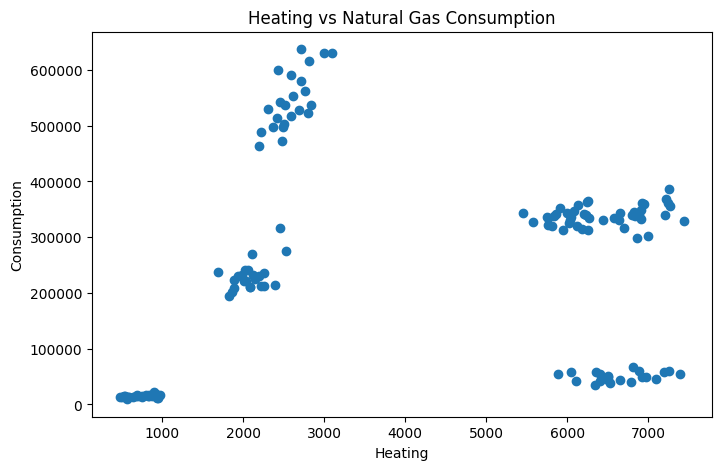

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['heating'], df['consumption'])

plt.xlabel("Heating")
plt.ylabel("Consumption")
plt.title("Heating vs Natural Gas Consumption")

plt.show()

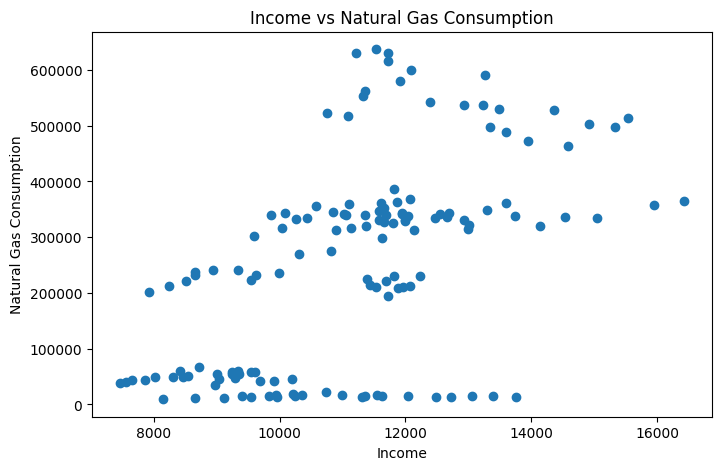

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['income'], df['consumption'])

plt.xlabel("Income")
plt.ylabel("Natural Gas Consumption")
plt.title("Income vs Natural Gas Consumption")

plt.show()

In [ ]:
X = df.drop('consumption', axis=1)

y = df['consumption']

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['rownames', 'state', 'statecode', 'year', 'price', 'eprice', 'oprice',
       'lprice', 'heating', 'income'],
      dtype='object')

Target:
consumption


In [ ]:
X = pd.get_dummies(X, drop_first=True)
print(X.head())
print(X.dtypes)
X = X.astype(float)

   rownames  statecode  year  price  eprice  oprice  lprice  heating  \
0         1         35  1967   1.42    2.98    7.40    1.47     6262   
1         2         35  1968   1.38    2.91    7.77    1.42     6125   
2         3         35  1969   1.37    2.84    7.96    1.38     6040   
3         4         35  1970   1.40    2.87    8.33    1.37     6085   
4         5         35  1971   1.50    3.07    8.80    1.40     5907   

     income  state_FL  state_MI  state_NY  state_TX  state_UT  
0  10903.75     False     False      True     False     False  
1  11370.02     False     False      True     False     False  
2  11578.68     False     False      True     False     False  
3  11586.77     False     False      True     False     False  
4  11657.42     False     False      True     False     False  
rownames       int64
statecode      int64
year           int64
price        float64
eprice       float64
oprice       float64
lprice       float64
heating        int64
income       fl

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (110, 14)
Testing data: (28, 14)


LINEAR REGRESSION


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_prediction = linear_model.predict(X_test)

EVALUATION


In [ ]:
linear_mae = mean_absolute_error(
    y_test,
    linear_prediction
)
linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_prediction
    )
)
linear_r2 = r2_score(
    y_test,
    linear_prediction
)
print("Linear Regression")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R2  :", linear_r2)

Linear Regression
MAE : 16719.874196968125
RMSE: 20860.824826612297
R2  : 0.9827906975201679


DECISION TREE

In [ ]:
from sklearn.tree import DecisionTreeRegressor
tree_model = DecisionTreeRegressor(
    random_state=42
)
tree_model.fit(
    X_train,
    y_train
)
tree_prediction = tree_model.predict(X_test)

EVALUATION


In [ ]:
tree_mae = mean_absolute_error(
    y_test,
    tree_prediction
)
tree_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tree_prediction
    )
)
tree_r2 = r2_score(
    y_test,
    tree_prediction
)
print("Decision Tree")
print("MAE :", tree_mae)
print("RMSE:", tree_rmse)
print("R2  :", tree_r2)

Decision Tree
MAE : 17737.14285714286
RMSE: 27623.671244061676
R2  : 0.9698239000827956


RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_prediction = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_prediction
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_prediction
    )
)

rf_r2 = r2_score(
    y_test,
    rf_prediction
)

print("Random Forest")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest
MAE : 11832.270714285713
RMSE: 18493.831275026543
R2 Score: 0.9864744760476343


COMPARISON


In [ ]:
results = pd.DataFrame({

    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        linear_mae,
        tree_mae,
        rf_mae
    ],

    'RMSE': [
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],

    'R2 Score': [
        linear_r2,
        tree_r2,
        rf_r2
    ]
})

print(results)

               Model           MAE          RMSE  R2 Score
0  Linear Regression  16719.874197  20860.824827  0.982791
1      Decision Tree  17737.142857  27623.671244  0.969824
2      Random Forest  11832.270714  18493.831275  0.986474


In [ ]:

best_model_name = results.loc[
    results['R2 Score'].idxmax(),
    'Model'
]

print("================================")
print("       BEST MODEL RESULT")
print("================================")

print("Best Model:", best_model_name)

print("\nModel Comparison:")
print(results)

       BEST MODEL RESULT
Best Model: Random Forest

Model Comparison:
               Model           MAE          RMSE  R2 Score
0  Linear Regression  16719.874197  20860.824827  0.982791
1      Decision Tree  17737.142857  27623.671244  0.969824
2      Random Forest  11832.270714  18493.831275  0.986474


In [ ]:
if best_model_name == "Linear Regression":
    best_model = linear_model
    best_prediction = linear_prediction

elif best_model_name == "Decision Tree":
    best_model = tree_model
    best_prediction = tree_prediction

else:
    best_model = rf_model
    best_prediction = rf_prediction

print("\nSelected Best Model:", best_model_name)


Selected Best Model: Random Forest


In [ ]:
final_prediction = best_model.predict(X_test)
print("\nFirst 10 Predictions:")
print(final_prediction[:10])


First 10 Predictions:
[222992.55  43828.83 334574.98  14642.24 341713.1  335580.62 328007.26
 558758.65  44810.24 218815.27]


In [ ]:
comparison = pd.DataFrame({
    'Actual Consumption': y_test.values,
    'Predicted Consumption': final_prediction
})
print(comparison.head(10))

   Actual Consumption  Predicted Consumption
0              210738              222992.55
1               57639               43828.83
2              313027              334574.98
3               14702               14642.24
4              341026              341713.10
5              348512              335580.62
6              330240              328007.26
7              562127              558758.65
8               54938               44810.24
9              237387              218815.27


In [ ]:
final_mae = mean_absolute_error(
    y_test,
    final_prediction
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_prediction
    )
)

final_r2 = r2_score(
    y_test,
    final_prediction
)

print("\n================================")
print("       FINAL MODEL PERFORMANCE")
print("================================")

print("Best Model :", best_model_name)
print("MAE        :", final_mae)
print("RMSE       :", final_rmse)
print("R2 Score   :", final_r2)


       FINAL MODEL PERFORMANCE
Best Model : Random Forest
MAE        : 11832.270714285713
RMSE       : 18493.831275026543
R2 Score   : 0.9864744760476343


In [ ]:
final_mae = mean_absolute_error(
    y_test,
    final_prediction
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_prediction
    )
)

final_r2 = r2_score(
    y_test,
    final_prediction
)

print("\n================================")
print("       FINAL MODEL PERFORMANCE")
print("================================")

print("Best Model :", best_model_name)
print("MAE        :", final_mae)
print("RMSE       :", final_rmse)
print("R2 Score   :", final_r2)


       FINAL MODEL PERFORMANCE
Best Model : Random Forest
MAE        : 11832.270714285713
RMSE       : 18493.831275026543
R2 Score   : 0.9864744760476343


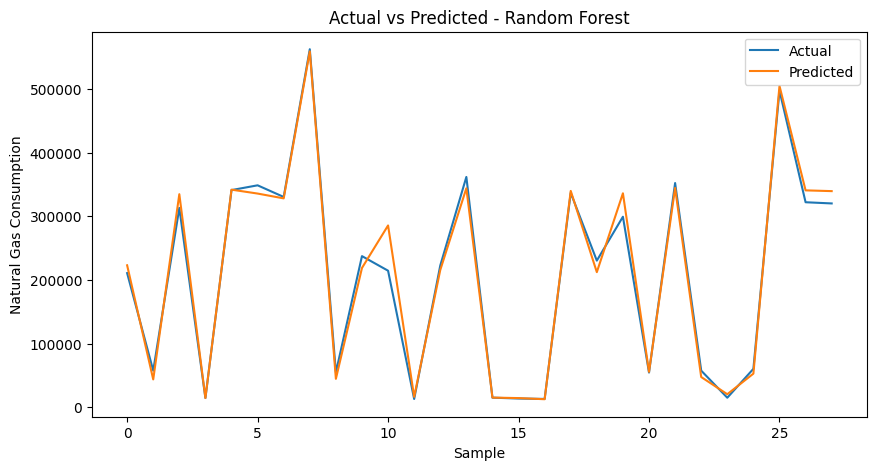

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(
    y_test.values[:50],
    label='Actual'
)
plt.plot(
    final_prediction[:50],
    label='Predicted'
)
plt.xlabel("Sample")
plt.ylabel("Natural Gas Consumption")

plt.title(
    f"Actual vs Predicted - {best_model_name}"
)
plt.legend()
plt.show()